# Лабораторная работа №4. Обнаружение аномалий в данных телеметрии оборудования

**Задача:** по временному ряду телеметрии промышленного оборудования получить массив бинарных меток
(1 — аномалия, 0 — норма) той же длины, что и исходные данные.

**Данные.** Предложенный в задании датасет с Kaggle требует авторизации, поэтому используется
открытый аналог из бенчмарка [Numenta Anomaly Benchmark (NAB)](https://github.com/numenta/NAB) —
`machine_temperature_system_failure.csv`: показания датчика температуры промышленной машины
(отсчёт каждые 5 минут, декабрь 2013 — февраль 2014). Для ряда известны 4 интервала аномалий,
один из которых — катастрофический отказ машины. Разметка берётся из `labels/combined_windows.json`
и используется **только для оценки качества** — обучение проводится без учителя.

**Метод.** В основе — подход из предложенной статьи (Applied Energy, 2020): рекуррентный
автоэнкодер на LSTM обучается восстанавливать окна нормального сигнала; на аномальных участках
ошибка реконструкции резко растёт, и по порогу на неё принимается решение об аномалии.
В качестве базового метода для сравнения используется Isolation Forest.

In [1]:
import json
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from sklearn.ensemble import IsolationForest
from sklearn.metrics import confusion_matrix, f1_score, precision_score, recall_score
from sklearn.preprocessing import StandardScaler

np.random.seed(42)
tf.random.set_seed(42)

DATA_DIR = os.path.join("..", "data")
CSV_NAME = "machine_temperature_system_failure.csv"

## 1. Загрузка данных и разметки

In [2]:
df = pd.read_csv(os.path.join(DATA_DIR, CSV_NAME), parse_dates=["timestamp"])
with open(os.path.join(DATA_DIR, "combined_windows.json")) as f:
    windows = json.load(f)[f"realKnownCause/{CSV_NAME}"]

df["label"] = 0
for start, end in windows:
    df.loc[(df.timestamp >= start) & (df.timestamp <= end), "label"] = 1

print(df.shape)
print(f"Доля точек внутри аномальных интервалов: {df.label.mean():.3f}")
df.head()

(22695, 3)
Доля точек внутри аномальных интервалов: 0.100


,timestamp,value,label
0,2013-12-02 21:15:00,73.967322,0
1,2013-12-02 21:20:00,74.935882,0
2,2013-12-02 21:25:00,76.124162,0
3,2013-12-02 21:30:00,78.140707,0
4,2013-12-02 21:35:00,79.329836,0


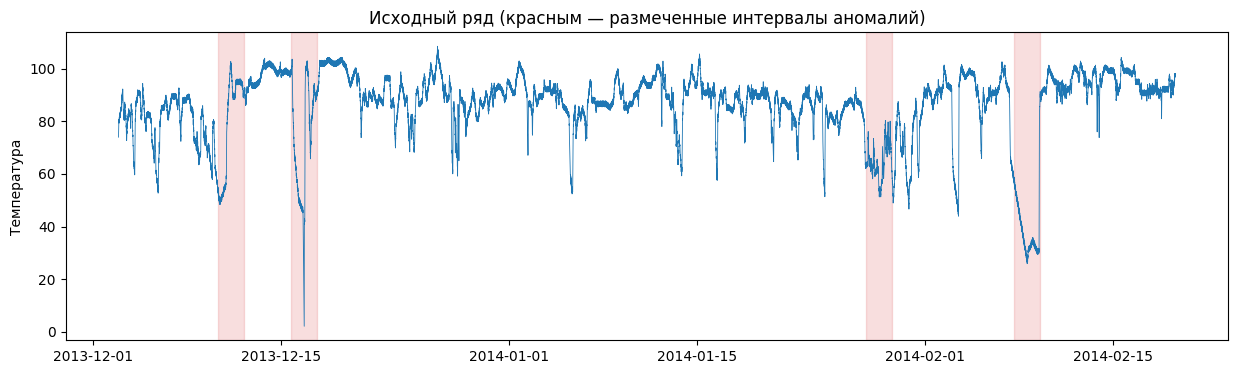

In [3]:
def plot_series(ax, title):
    ax.plot(df.timestamp, df.value, lw=0.6, color="tab:blue")
    for start, end in windows:
        ax.axvspan(pd.Timestamp(start), pd.Timestamp(end), color="tab:red", alpha=0.15)
    ax.set_title(title)
    ax.set_ylabel("Температура")


fig, ax = plt.subplots(figsize=(15, 4))
plot_series(ax, "Исходный ряд (красным — размеченные интервалы аномалий)")
plt.show()

## 2. Подготовка данных

Ряд стандартизуется и нарезается скользящими окнами длиной 48 отсчётов (4 часа) с шагом 1.
Автоэнкодер обучается на всех окнах: аномалии составляют малую долю данных, поэтому модель
в основном выучивает нормальное поведение.

In [4]:
WINDOW = 48

scaler = StandardScaler()
values = scaler.fit_transform(df[["value"]]).astype("float32")


def make_windows(x, size):
    return np.lib.stride_tricks.sliding_window_view(x[:, 0], size)[..., None].copy()


X = make_windows(values, WINDOW)
print("Окна:", X.shape)

Окна: (22648, 48, 1)


## 3. LSTM-автоэнкодер

In [5]:
def build_autoencoder(window, latent=16):
    inp = tf.keras.Input(shape=(window, 1))
    x = tf.keras.layers.LSTM(32, return_sequences=True)(inp)
    z = tf.keras.layers.LSTM(latent)(x)
    x = tf.keras.layers.RepeatVector(window)(z)
    x = tf.keras.layers.LSTM(latent, return_sequences=True)(x)
    x = tf.keras.layers.LSTM(32, return_sequences=True)(x)
    out = tf.keras.layers.TimeDistributed(tf.keras.layers.Dense(1))(x)
    return tf.keras.Model(inp, out, name="lstm_autoencoder")


model = build_autoencoder(WINDOW)
model.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss="mae")
model.summary()

Model: "lstm_autoencoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 48, 1)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 48, 32)         │         4,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 16)             │         3,136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ repeat_vector (RepeatVector)    │ (None, 48, 16)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_2 (LSTM)                   │ (None, 48, 16)         │         2,112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_3 (LSTM)                   │ (None, 48, 32)         │         6,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed                │ (None, 48, 1)          │            33 │
│ (TimeDistributed)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 15,905 (62.13 KB)

 Trainable params: 15,905 (62.13 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/15


160/160 - 23s - 145ms/step - loss: 0.2551 - val_loss: 0.1174


Epoch 2/15


160/160 - 11s - 67ms/step - loss: 0.1520 - val_loss: 0.0951


Epoch 3/15


...

160/160 - 13s - 81ms/step - loss: 0.0662 - val_loss: 0.0600


Epoch 14/15


160/160 - 13s - 82ms/step - loss: 0.0648 - val_loss: 0.0588


Epoch 15/15


160/160 - 13s - 84ms/step - loss: 0.0645 - val_loss: 0.0581


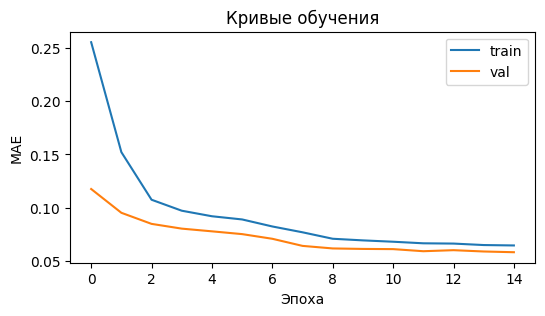

In [6]:
history = model.fit(
    X, X,
    epochs=15,
    batch_size=128,
    validation_split=0.1,
    shuffle=True,
    callbacks=[tf.keras.callbacks.EarlyStopping(patience=3, restore_best_weights=True)],
    verbose=2,
)

plt.figure(figsize=(6, 3))
plt.plot(history.history["loss"], label="train")
plt.plot(history.history["val_loss"], label="val")
plt.xlabel("Эпоха"); plt.ylabel("MAE"); plt.legend(); plt.title("Кривые обучения")
plt.show()

## 4. Ошибка реконструкции и порог

Для каждой точки ряда ошибка усредняется по всем окнам, в которые она попала. Затем ошибка
сглаживается скользящим средним (1 час), а порог выбирается как $\mu + 3\sigma$ сглаженной ошибки.

In [7]:
recon = model.predict(X, batch_size=512, verbose=0)
err_windows = np.abs(recon - X)[..., 0]  # (n_windows, WINDOW)

n = len(values)
point_err = np.zeros(n)
counts = np.zeros(n)
for k in range(WINDOW):
    point_err[k:k + len(X)] += err_windows[:, k]
    counts[k:k + len(X)] += 1
point_err /= counts

df["ae_score"] = pd.Series(point_err).rolling(12, center=True, min_periods=1).mean()
threshold = df.ae_score.mean() + 3 * df.ae_score.std()
df["ae_anomaly"] = (df.ae_score > threshold).astype(int)
print(f"Порог: {threshold:.4f}, помечено точек: {df.ae_anomaly.sum()}")

Порог: 0.2157, помечено точек: 290


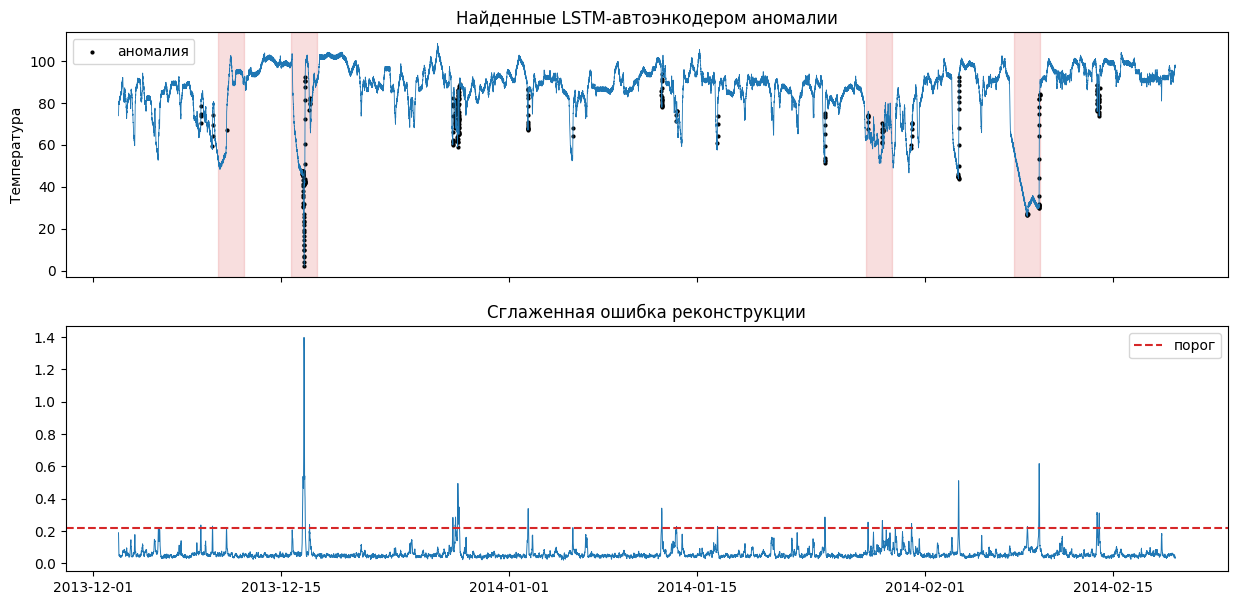

In [8]:
fig, axes = plt.subplots(2, 1, figsize=(15, 7), sharex=True)
plot_series(axes[0], "Найденные LSTM-автоэнкодером аномалии")
axes[0].scatter(df.timestamp[df.ae_anomaly == 1], df.value[df.ae_anomaly == 1], s=4, color="black", label="аномалия")
axes[0].legend()
axes[1].plot(df.timestamp, df.ae_score, lw=0.7)
axes[1].axhline(threshold, color="tab:red", ls="--", label="порог")
axes[1].set_title("Сглаженная ошибка реконструкции"); axes[1].legend()
plt.show()

## 5. Базовый метод: Isolation Forest

Признаки точки: значение, скользящие среднее и стандартное отклонение за 1 час, первая разность.
Доля аномалий (`contamination`) задаётся равной доле точек, помеченных автоэнкодером, чтобы методы
сравнивались при одинаковом числе срабатываний.

In [9]:
feats = pd.DataFrame({
    "value": values[:, 0],
    "roll_mean": pd.Series(values[:, 0]).rolling(12, min_periods=1).mean(),
    "roll_std": pd.Series(values[:, 0]).rolling(12, min_periods=1).std().fillna(0),
    "diff": pd.Series(values[:, 0]).diff().fillna(0),
})
contamination = max(df.ae_anomaly.mean(), 0.005)
iso = IsolationForest(n_estimators=300, contamination=contamination, random_state=42)
df["if_anomaly"] = (iso.fit_predict(feats) == -1).astype(int)
print(f"Isolation Forest: помечено точек {df.if_anomaly.sum()}")

Isolation Forest: помечено точек 290


## 6. Оценка качества

Метрики считаются двумя способами:
* **поточечно** — precision / recall / F1 по меткам каждой точки. Интервалы NAB очень широкие
  (по 2 суток вокруг события), поэтому поточечный recall заведомо невысок;
* **по событиям** — сколько из 4 размеченных интервалов содержат хотя бы одно срабатывание и сколько
  отдельных срабатываний (связных групп точек) попало вне интервалов (ложные тревоги).

In [10]:
def segments(mask):
    """Связные группы единиц в бинарной маске: список (start, end)."""
    m = np.r_[0, mask, 0]
    d = np.diff(m)
    return list(zip(np.where(d == 1)[0], np.where(d == -1)[0]))


def evaluate(pred):
    y = df.label.values
    detected = sum(pred[(df.timestamp >= s) & (df.timestamp <= e)].any() for s, e in windows)
    false_alarms = sum(1 for a, b in segments(pred) if y[a:b].sum() == 0)
    return {
        "precision": precision_score(y, pred, zero_division=0),
        "recall": recall_score(y, pred, zero_division=0),
        "F1": f1_score(y, pred, zero_division=0),
        "найдено событий": f"{detected}/{len(windows)}",
        "ложных тревог": false_alarms,
    }


results = pd.DataFrame({
    "LSTM-автоэнкодер": evaluate(df.ae_anomaly.values),
    "Isolation Forest": evaluate(df.if_anomaly.values),
}).T
results

,precision,recall,F1,найдено событий,ложных тревог
LSTM-автоэнкодер,0.37931,0.048501,0.086005,4/4,16
Isolation Forest,0.696552,0.089065,0.157936,4/4,33


Матрица ошибок LSTM-автоэнкодера:
[[20247   180]
 [ 2158   110]]


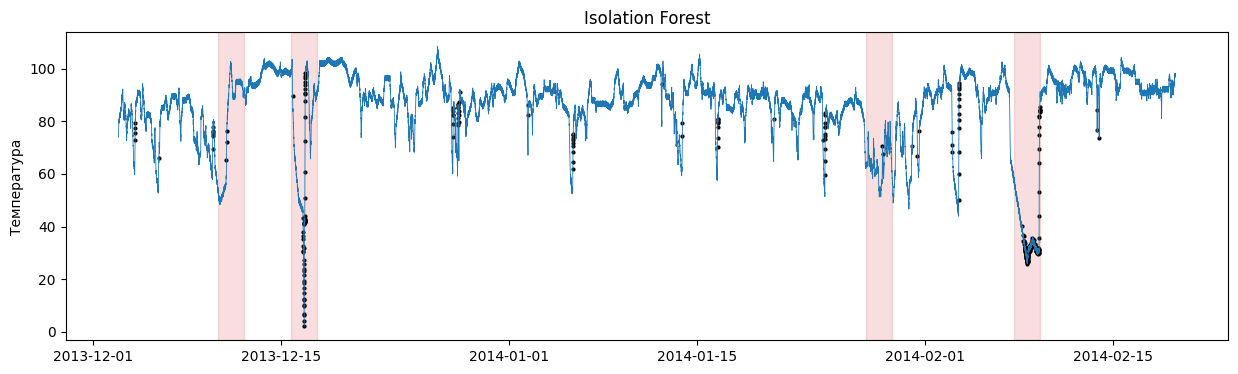

In [11]:
print("Матрица ошибок LSTM-автоэнкодера:")
print(confusion_matrix(df.label, df.ae_anomaly))

fig, ax = plt.subplots(figsize=(15, 4))
plot_series(ax, "Isolation Forest")
ax.scatter(df.timestamp[df.if_anomaly == 1], df.value[df.if_anomaly == 1], s=4, color="black")
plt.show()

## 7. Результат: массив бинарных значений

Выход системы — массив меток той же длины, что и входные данные телеметрии. Он сохраняется в
`anomalies.csv` (столбцы `timestamp`, `value`, `anomaly`).

In [12]:
out = df[["timestamp", "value"]].assign(anomaly=df.ae_anomaly)
out.to_csv("anomalies.csv", index=False)
print(out.anomaly.values[:20], "...", f"длина {len(out)}, аномалий {out.anomaly.sum()}")
out[out.anomaly == 1].head()

[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0] ... длина 22695, аномалий 290


,timestamp,value,anomaly
1766,2013-12-09 00:25:00,70.426586,1
1767,2013-12-09 00:30:00,74.012063,1
1768,2013-12-09 00:35:00,74.655431,1
1769,2013-12-09 00:40:00,78.563800,1
2017,2013-12-09 21:20:00,59.724992,1


## Выводы

* LSTM-автоэнкодер, обученный без учителя на окнах ряда, выделяет участки, где поведение сигнала
  отличается от типичного: резкие провалы температуры и нетипичные колебания дают всплеск ошибки
  реконструкции.
* Оба метода нашли все 4 размеченных события. Isolation Forest даёт более высокую поточечную
  precision: аномалии этого ряда — в основном глубокие провалы температуры, и экстремальное значение
  точки само по себе хорошо их выдаёт. Зато у него примерно вдвое больше ложных тревог (16 против 33
  в таблице выше), так как он срабатывает на любое низкое значение, в том числе на штатные снижения.
* Автоэнкодер реагирует на **форму** сигнала в окне: срабатывания сосредоточены на резких переходах
  (начало и конец провала, обрыв перед отказом 2014-02-08), а длительное плато внутри аномалии он
  постепенно «выучивает» и перестаёт выделять. Отсюда меньше ложных тревог, но ниже поточечный recall.
* Поточечные метрики занижены из-за ширины размеченных интервалов NAB (по 2 суток); для практики
  важнее событийная оценка — доля найденных отказов и число ложных тревог.
* Улучшить результат можно подбором длины окна и порога (например, по валидационному отрезку),
  а также переходом к многомерной телеметрии, если доступны несколько датчиков.